# AI/ML Engineer: Technical Take-Home Assignment

## Reporting scope

This notebook analyses Harbourview House’s referrals, admissions,
occupancy, length of stay, and follow-up outcomes for the director
and funders.

The reporting year is **January 1–December 31, 2025**, chosen because
the dataset covers the full calendar year.

- Data quality checks will cover the full dataset. Each metric will
  explain which residents and dates are included.
- Events in 2026 will not count towards 2025 totals. Earlier admissions
  will contribute to occupancy where their stays overlap 2025.
- Admission and discharge dates will be used to assess occupancy at
  year end. Current status may reflect later changes, and missing
  dates may leave some stays uncertain.
- We assume follow-ups are due six and twelve months after discharge. Each percentage includes all residents due by December 31, 2025, with lost-to-follow-up, unknown, and missing outcomes shown separately. Discharged residents with missing discharge dates are reported as eligibility unknown and excluded from these percentages. Results describe outcomes recorded in the supplied dataset; collection dates are unavailable, so we cannot confirm they were known at year end.

Missing or inconsistent records will be reviewed before calculating
metrics. Any exclusions or assumptions will be explained alongside
the results.

In [68]:
import pandas as pd
from pathlib import Path
DATA_PATH = Path("data/harbourview_residents.csv")

In [69]:
date_columns = [
    "referral_date",
    "intake_date",
    "admission_date",
    "discharge_date",
]
df = pd.read_csv(DATA_PATH, parse_dates=date_columns)

In [70]:
df.head()

,resident_id,referral_date,intake_date,admission_date,current_status,discharge_date,discharge_reason,entrance_fee,fee_waived,followup_6m,followup_12m,staff_note,bed_capacity
0,HV-0001,2024-07-05,NaT,NaT,not_admitted,NaT,NaN,NaN,NaN,NaN,NaN,Phone disconnected. Closed referral.,24
1,HV-0002,2024-07-13,2024-07-18,NaT,not_admitted,NaT,NaN,1250.0,False,NaN,NaN,Waitlisted. f/u call next wk,24
2,HV-0003,2024-07-17,NaT,NaT,not_admitted,NaT,NaN,NaN,NaN,NaN,NaN,Phone disconnected. Closed referral.,24
3,HV-0004,2024-07-20,2024-07-24,2024-07-27,discharged,2024-10-16,transfer,750.0,False,relapse_reported,relapse_reported,transferred to higher level of care (detox),24
4,HV-0005,2024-07-21,2024-07-30,2024-08-03,discharged,2024-10-05,administrative,0.0,True,lost_to_follow_up,lost_to_follow_up,admin d/c - violence policy,24


In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   resident_id       200 non-null    object        
 1   referral_date     200 non-null    datetime64[ns]
 2   intake_date       144 non-null    datetime64[ns]
 3   admission_date    110 non-null    datetime64[ns]
 4   current_status    200 non-null    object        
 5   discharge_date    92 non-null     datetime64[ns]
 6   discharge_reason  93 non-null     object        
 7   entrance_fee      150 non-null    float64       
 8   fee_waived        150 non-null    object        
 9   followup_6m       91 non-null     object        
 10  followup_12m      95 non-null     object        
 11  staff_note        192 non-null    object        
 12  bed_capacity      200 non-null    int64         
dtypes: datetime64[ns](4), float64(1), int64(1), object(7)
memory usage: 20.4+ KB


In [72]:
df["fee_waived"] = df["fee_waived"].astype("boolean")

In [25]:
display(
    df.isna()
    .sum()
    .rename("Missing values")
    .to_frame()
)

display(
    df["current_status"]
    .value_counts()
    .rename_axis("Current status")
    .rename("Residents")
    .to_frame()
)

,Missing values
resident_id,0
referral_date,0
intake_date,56
admission_date,90
current_status,0
discharge_date,108
discharge_reason,107
entrance_fee,50
fee_waived,50
followup_6m,109


,Residents
Current status,
not_admitted,90
discharged,50
alumni,24
aftercare,21
phase_2,6
phase_1,5
phase_3,4


In [73]:
checks = {
    "Missing resident ID": df["resident_id"].isna(),
    "Duplicate resident ID": (
        df["resident_id"].notna()
        & df["resident_id"].duplicated(keep=False)
    ),
    "Intake before referral": (
        df["intake_date"] < df["referral_date"]
    ),
    "Admission before referral": (
        df["admission_date"] < df["referral_date"]
    ),
    "Admission before intake": (
        df["admission_date"] < df["intake_date"]
    ),
    "Admission without an intake date": (
        df["admission_date"].notna()
        & df["intake_date"].isna()
    ),
}

for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

Missing resident ID: 0
Duplicate resident ID: 0
Intake before referral: 2
Admission before referral: 0
Admission before intake: 0
Admission without an intake date: 6


In [74]:
issues = (
    (df["intake_date"] < df["referral_date"])
    | (
        df["admission_date"].notna()
        & df["intake_date"].isna()
    )
)

display(
    df.loc[
        issues,
        [
            "resident_id",
            "referral_date",
            "intake_date",
            "admission_date",
        ],
    ].sort_values("referral_date")
)

,resident_id,referral_date,intake_date,admission_date
8,HV-0009,2024-08-07,NaT,2024-08-15
40,HV-0041,2024-11-02,2024-10-31,2024-11-17
71,HV-0072,2025-02-09,NaT,2025-02-22
94,HV-0095,2025-03-16,NaT,2025-04-05
113,HV-0114,2025-05-07,NaT,2025-05-16
148,HV-0149,2025-08-13,2025-08-09,2025-08-20
149,HV-0150,2025-08-21,NaT,2025-08-30
154,HV-0155,2025-08-28,NaT,2025-09-11


The full dataset contains two intake dates before referral and six admissions without intake dates. Within the 2025 referral cohort, one intake date is invalid and five are missing.
These residents are retained, and their valid admissions count towards overall referral-to-admission conversion. Calculations requiring valid intake dates exclude these records, with exclusions reported. No dates have been changed.

# Select the 2025 referral cohort

In [75]:
year_start = pd.Timestamp("2025-01-01")
year_end = pd.Timestamp("2026-01-01")

referral_cohort = df[
    (df["referral_date"] >= year_start)
    & (df["referral_date"] < year_end)
].copy()

print("Referrals in 2025:", len(referral_cohort))

Referrals in 2025: 141


The result is 141 residents. We follow this same group through intake and admission for the funnel.

# Funnel counts and conversion rates

In [38]:
# Intake must be on or after referral and before year end.
intake = (
    (referral_cohort["intake_date"] >= referral_cohort["referral_date"])
    & (referral_cohort["intake_date"] < year_end)
)

# Admissions are counted even when the intake date is missing.
admission = (
    (referral_cohort["admission_date"] >= referral_cohort["referral_date"])
    & (referral_cohort["admission_date"] < year_end)
)

# Both stages must have valid dates in the correct order.
both_stages = (
    intake & admission
    & (referral_cohort["admission_date"] >= referral_cohort["intake_date"])
)

funnel = pd.DataFrame({
    "Conversion": [
        "Referral → intake",
        "Intake → admission",
        "Referral → admission",
    ],
    "Converted": [
        intake.sum(),
        both_stages.sum(),
        admission.sum(),
    ],
    "Total": [
        len(referral_cohort),
        intake.sum(),
        len(referral_cohort),
    ],
})

funnel["Rate (%)"] = funnel["Converted"] / funnel["Total"] * 100
funnel["Rate (%)"] = funnel["Rate (%)"].round(1)

display(funnel)

,Conversion,Converted,Total,Rate (%)
0,Referral → intake,101,141,71.6
1,Intake → admission,70,101,69.3
2,Referral → admission,76,141,53.9


Of 141 residents referred in 2025, 101 had a valid intake recorded by
year end (71.6%), and 76 had a recorded admission (53.9%).

Of the 101 residents with valid intake dates, 70 progressed to admission
(69.3%). The other six recorded admissions had five missing intake dates
and one intake date before referral, so they are included only in the
overall referral-to-admission rate.

# Median and P90 time between stages

In [41]:
intake_residents = referral_cohort[intake]
admitted_residents = referral_cohort[both_stages]

referral_days = (
    intake_residents["intake_date"] - intake_residents["referral_date"]
).dt.days

admission_days = (
    admitted_residents["admission_date"] - admitted_residents["intake_date"]
).dt.days

waiting_times = pd.DataFrame({
    "Referral → intake": referral_days,
    "Intake → admission": admission_days,
})

summary = pd.DataFrame({
    "Residents": waiting_times.count(),
    "Median days": waiting_times.median(),
    "P90 days": waiting_times.quantile(0.9),
})

display(summary.round(1))

,Residents,Median days,P90 days
Referral → intake,101,6.0,18.0
Intake → admission,70,8.5,26.0


For residents referred in 2025, the median time from referral to intake was 6 days, and 90% of valid transitions took 18 days or less (101 residents). From intake to admission, the median was 8.5 days, and 90% took 26 days or less (70 residents).
These waiting times include only valid transitions completed by December 31, 2025. Residents without a recorded next stage still count in the conversion-rate denominator, but not in the waiting-time calculations. Excluding unfinished waits may make waiting times appear shorter. A missing date does not tell us whether someone is still waiting, withdrew, or has an incomplete record.

/Users/komalpreet/miniconda3/envs/inflection/lib/python3.11/site-packages/plotly/io/_renderers.py:58: UserWarning: Plotly version >= 6 requires JupyterLab >= 3 but you have 2.3.2 installed. To upgrade JupyterLab, please run `pip install jupyterlab --upgrade`.
  warnings.warn(


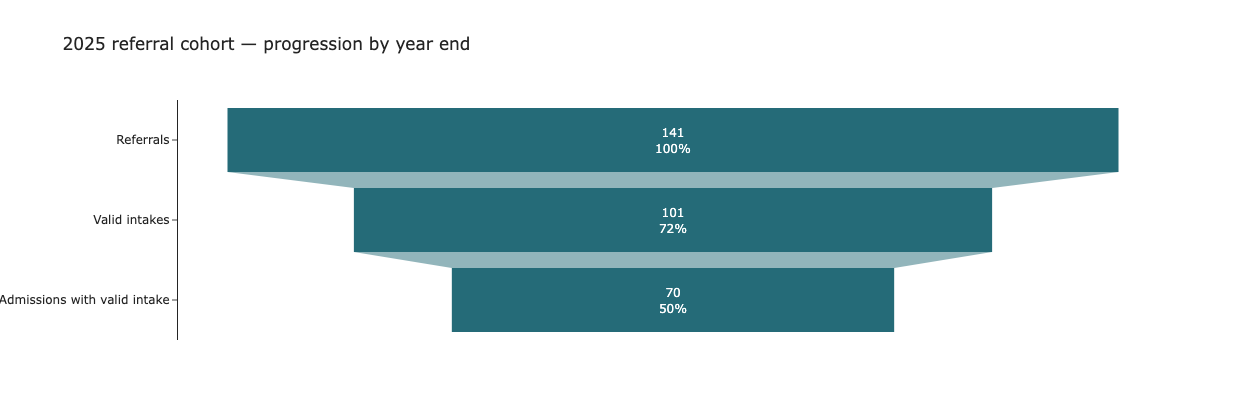

In [78]:
import plotly.graph_objects as go

fig = go.Figure(go.Funnel(
    y=["Referrals", "Valid intakes", "Admissions with valid intake"],
    x=[len(referral_cohort), intake.sum(), both_stages.sum()],
    textinfo="value+percent initial",
    marker_color="#256B78",
))

fig.update_layout(
    title="2025 referral cohort — progression by year end",
    template="simple_white",
    width=750,
    height=420,
)

fig.show(config={"displayModeBar": False})

/Users/komalpreet/miniconda3/envs/inflection/lib/python3.11/site-packages/plotly/io/_renderers.py:58: UserWarning: Plotly version >= 6 requires JupyterLab >= 3 but you have 2.3.2 installed. To upgrade JupyterLab, please run `pip install jupyterlab --upgrade`.
  warnings.warn(


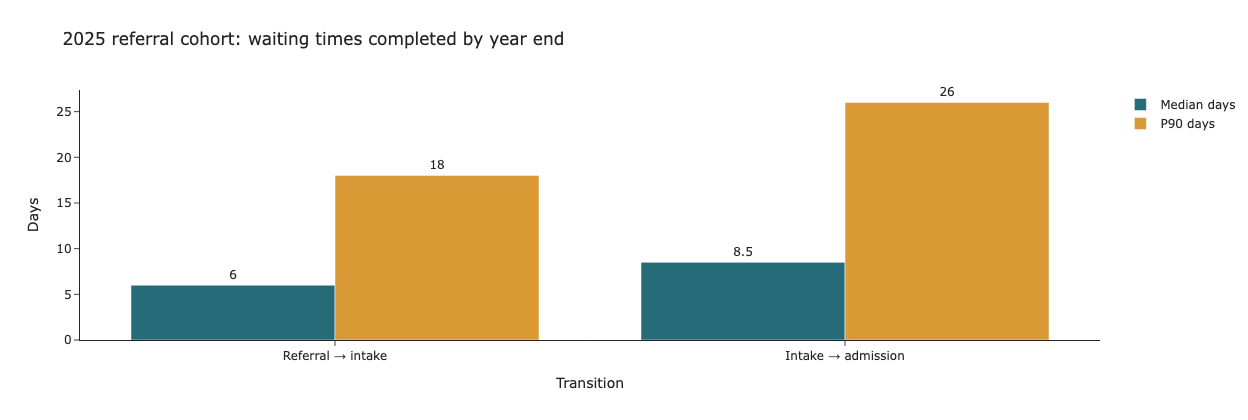

In [83]:
fig = px.bar(
    summary,
    x=summary.index,
    y=["Median days", "P90 days"],
    barmode="group",
    color_discrete_map={
        "Median days": "#256B78",
        "P90 days": "#D99A36",
    },
    labels={
        "index": "Transition",
        "value": "Days",
        "variable": "Measure",
    },
    title="2025 referral cohort: waiting times completed by year end",
    template="simple_white",
    width=800,
    height=420,
)

fig.update_traces(
    texttemplate="%{y:~g}",
    textposition="outside",
    cliponaxis=False,
    hovertemplate="%{x}<br>%{y:~g} days<extra></extra>",
)

fig.update_layout(margin=dict(t=90))

fig.update_layout(legend_title_text="")
fig.update_yaxes(rangemode="tozero", tickformat="~g")

fig.show(config={"displayModeBar": False})

## Occupancy and length of stay

Admission day counts as occupied; discharge day does not.
Stays are limited to the 2025 reporting period for occupancy.

In [85]:
exit_statuses = ["discharged", "alumni", "aftercare"]

missing_discharge = df[
    df["current_status"].isin(exit_statuses)
    & df["discharge_date"].isna()
]

print("Bed capacity:", df["bed_capacity"].unique())
print("Exit statuses missing discharge dates:", len(missing_discharge))
print(
    "Discharge before admission:",
    (df["discharge_date"] < df["admission_date"]).sum(),
)

display(
    missing_discharge[
        ["resident_id", "admission_date", "current_status", "discharge_date"]
    ]
)

Bed capacity: [24]
Exit statuses missing discharge dates: 3
Discharge before admission: 0


,resident_id,admission_date,current_status,discharge_date
30,HV-0031,2024-10-07,discharged,NaT
71,HV-0072,2025-02-22,discharged,NaT
135,HV-0136,2025-07-27,discharged,NaT


Three residents are marked as discharged but have no discharge date.
Their length of stay and monthly occupancy contribution cannot be
determined reliably, so they are excluded from these calculations.
This may understate occupancy. They are not classified as ongoing stays.

In [86]:
capacity = df["bed_capacity"].iloc[0]
stays = df.drop(index=missing_discharge.index)
days = pd.date_range(year_start, year_end, inclusive="left")

daily_occupancy = pd.Series(0, index=days)

for day in days:
    admitted = stays["admission_date"] <= day
    discharged = stays["discharge_date"] <= day
    daily_occupancy.loc[day] = (admitted & ~discharged).sum()

monthly_occupancy = daily_occupancy.resample("MS").mean()
monthly_occupancy = monthly_occupancy.to_frame("Average occupied beds")

monthly_occupancy["Capacity"] = capacity
monthly_occupancy["Occupancy (%)"] = (
    monthly_occupancy["Average occupied beds"] / capacity * 100
)

display(monthly_occupancy.round(1))

,Average occupied beds,Capacity,Occupancy (%)
2025-01-01,20.3,24,84.4
2025-02-01,20.7,24,86.2
2025-03-01,22.2,24,92.5
2025-04-01,23.4,24,97.6
2025-05-01,23.5,24,98.1
2025-06-01,22.6,24,94.3
2025-07-01,21.5,24,89.5
2025-08-01,17.6,24,73.3
2025-09-01,19.6,24,81.5
2025-10-01,23.8,24,99.2


/Users/komalpreet/miniconda3/envs/inflection/lib/python3.11/site-packages/plotly/io/_renderers.py:58: UserWarning: Plotly version >= 6 requires JupyterLab >= 3 but you have 2.3.2 installed. To upgrade JupyterLab, please run `pip install jupyterlab --upgrade`.
  warnings.warn(


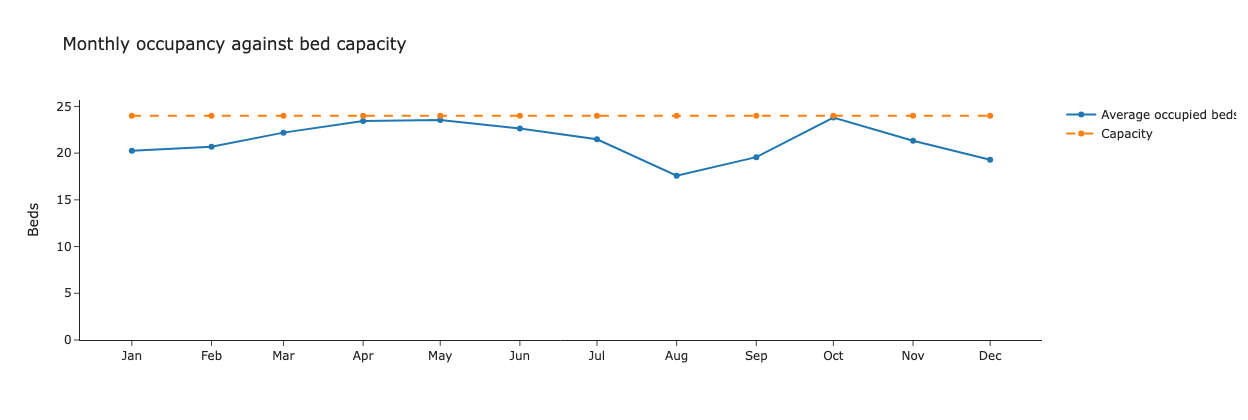

In [87]:
fig = px.line(
    monthly_occupancy,
    y=["Average occupied beds", "Capacity"],
    markers=True,
    title="Monthly occupancy against bed capacity",
    labels={"index": "Month", "value": "Beds", "variable": ""},
    template="simple_white",
    width=750,
    height=420,
)

fig.update_traces(
    line_dash="dash",
    selector={"name": "Capacity"},
)
fig.update_xaxes(dtick="M1", tickformat="%b", title=None)
fig.update_yaxes(rangemode="tozero")

fig.show(config={"displayModeBar": False})

In [61]:
# Use stays retained after excluding unknown discharge dates.
year_stays = stays[
    (stays["admission_date"] < year_end)
    & (
        stays["discharge_date"].isna()
        | (stays["discharge_date"] >= year_start)
    )
].copy()

completed = year_stays[
    year_stays["discharge_date"] < year_end
].copy()

ongoing = year_stays[
    year_stays["discharge_date"].isna()
    | (year_stays["discharge_date"] >= year_end)
].copy()

completed["Stay days"] = (
    completed["discharge_date"] - completed["admission_date"]
).dt.days

ongoing["Days observed"] = (
    year_end - ongoing["admission_date"]
).dt.days

los_summary = pd.DataFrame({
    "Completed stays": completed["Stay days"].agg(["count", "median"]),
    "Ongoing stays": ongoing["Days observed"].agg(["count", "median"]),
})

display(los_summary)

,Completed stays,Ongoing stays
count,80.0,18.0
median,95.0,70.0


There were 80 completed stays, with a median length of 95 days. The 18 ongoing stays were right-censored at December 31, 2025, with a median observed duration of 70 days. These ongoing durations are reported separately because they are not final stay lengths. Three discharged residents with missing discharge dates were excluded because their stay endings could not be determined.

# Honest funder outcomes

In [90]:
cutoff = year_end - pd.Timedelta(days=1)

valid_discharge = (
    df["admission_date"].notna()
    & (df["discharge_date"] >= df["admission_date"])
    & (df["discharge_date"] <= cutoff)
)

for months in [6, 12]:
    due_date = df["discharge_date"] + pd.DateOffset(months=months)
    eligible = valid_discharge & (due_date <= cutoff)

    outcomes = df.loc[eligible, f"followup_{months}m"].fillna("missing")
    denominator = len(outcomes)

    results = (
        outcomes.value_counts()
        .rename_axis("Outcome")
        .reset_index(name="Residents")
    )

    results["Outcome"] = (
        results["Outcome"].str.replace("_", " ").str.capitalize()
    )
    results["Denominator"] = denominator
    results["Rate (%)"] = (
        (results["Residents"] / denominator * 100).round(1)
        if denominator else float("nan")
    )

    print(f"\n{months}-month follow-up — due by {cutoff.date()}")
    print("Not yet due:", (valid_discharge & (due_date > cutoff)).sum())

    display(
        results.style
        .hide(axis="index")
        .format({"Rate (%)": "{:.1f}"})
    )

unknown_eligibility = (
    df["current_status"].isin(["discharged", "alumni", "aftercare"])
    & df["discharge_date"].isna()
    & (df["admission_date"] < year_end)
)

print(
    "\nDischarged residents with unknown follow-up eligibility:",
    unknown_eligibility.sum(),
)


6-month follow-up — due by 2025-12-31
Not yet due: 43


Outcome,Residents,Denominator,Rate (%)
Engaged in recovery,21,45,46.7
Lost to follow up,13,45,28.9
Relapse reported,6,45,13.3
Missing,3,45,6.7
Unknown,2,45,4.4



12-month follow-up — due by 2025-12-31
Not yet due: 80


Outcome,Residents,Denominator,Rate (%)
Lost to follow up,5,8,62.5
Relapse reported,2,8,25.0
Engaged in recovery,1,8,12.5



Discharged residents with unknown follow-up eligibility: 3


/Users/komalpreet/miniconda3/envs/inflection/lib/python3.11/site-packages/plotly/io/_renderers.py:58: UserWarning: Plotly version >= 6 requires JupyterLab >= 3 but you have 2.3.2 installed. To upgrade JupyterLab, please run `pip install jupyterlab --upgrade`.
  warnings.warn(


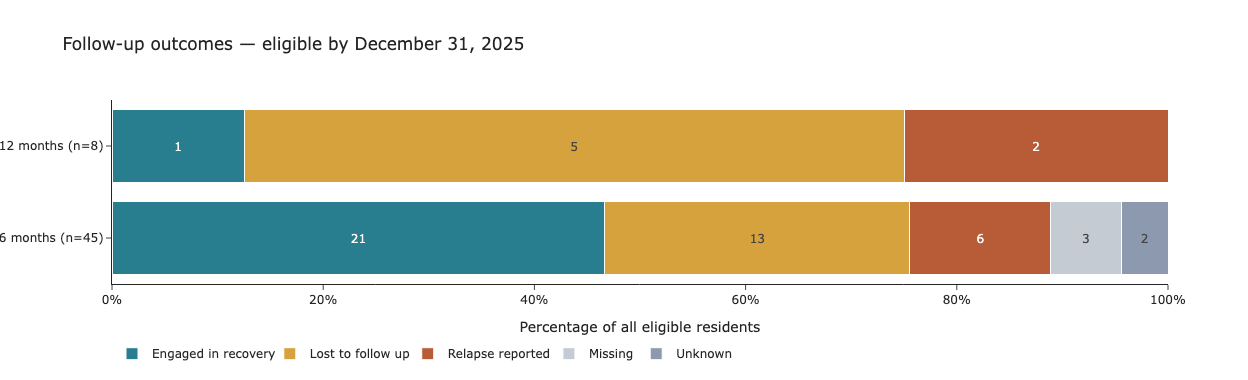

In [92]:
fig = px.bar(
    chart_data,
    x="Rate (%)",
    y="Follow-up",
    color="Outcome",
    orientation="h",
    text="Residents",
    title="Follow-up outcomes — eligible by December 31, 2025",
    color_discrete_sequence=[
        "#287D8E", "#D6A23D", "#B85C38", "#C5CBD3", "#8D99AE"
    ],
    template="simple_white",
    width=900,
    height=380,
)

fig.update_traces(
    textposition="inside",
    insidetextanchor="middle",
    marker_line_color="white",
    marker_line_width=1,
)

fig.update_layout(
    barmode="stack",
    legend=dict(orientation="h", y=-0.3, title=None),
    yaxis_title=None,
    uniformtext_minsize=11,
    uniformtext_mode="hide",
)

fig.update_xaxes(
    range=[0, 100],
    title="Percentage of all eligible residents",
    ticksuffix="%",
)

fig.show(config={"displayModeBar": False})